# 02 · Real data and LightGBM
Dataset: **Store Sales - Time Series Forecasting** (Kaggle, Favorita retail, Ecuador).
Goal: compare the seasonal naive, ETS and LightGBM on a real series, with expanding-window backtesting (28-day horizon).

## 1. Data
Dataset: **Store Sales - Time Series Forecasting** (Kaggle). To reproduce the experiment: accept the competition rules on Kaggle, save your API key in the Colab Secrets as `KAGGLE_API_TOKEN` (never in the code) and run the cell below.

In [ ]:
import os
from google.colab import userdata

!pip install -q -U kaggle
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle competitions download -c store-sales-time-series-forecasting -p data
!unzip -oq data/store-sales-time-series-forecasting.zip -d data
!ls data

100% 21.4M/21.4M [00:00<00:00, 158MB/s]

holidays_events.csv			 stores.csv
oil.csv					 test.csv
sample_submission.csv			 train.csv
store-sales-time-series-forecasting.zip  transactions.csv


## 2. Loading and choosing the series
We start from a single series (store 1, family GROCERY I). On 25 December the stores are closed and there are no rows: we fill the gap by interpolation.

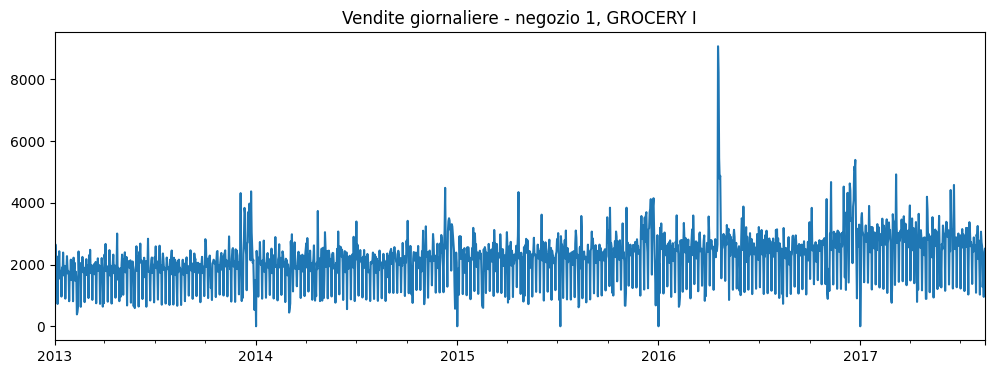

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import lightgbm as lgb
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")

STORE, FAMILY = 1, "GROCERY I"
H = 28   # forecast horizon (days)

train = pd.read_csv("data/train.csv", parse_dates=["date"])
hol = pd.read_csv("data/holidays_events.csv", parse_dates=["date"])

s = train[(train.store_nbr == STORE) & (train.family == FAMILY)].set_index("date")
s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"))
s["sales"] = s["sales"].interpolate()
s["onpromotion"] = s["onpromotion"].fillna(0)

# national holidays actually celebrated
nat = hol[(hol.locale == "National") & (~hol.transferred) & (hol.type != "Work Day")]
holiday_dates = set(nat.date)

s["sales"].plot(figsize=(12, 4), title=f"Daily sales - store {STORE}, {FAMILY}")
plt.show()

## 3. Features for LightGBM
Anti-leakage rule: lags and moving averages use only data from at least 28 days earlier (the horizon), so we can forecast all 28 days in one go. Promotions and holidays are known in advance, so they can be used.

In [ ]:
def make_features(s):
    X = pd.DataFrame(index=s.index)
    y = s["sales"]
    X["dow"] = X.index.dayofweek
    X["dom"] = X.index.day
    X["month"] = X.index.month
    X["doy"] = X.index.dayofyear
    X["payday"] = ((X.index.day == 15) | X.index.is_month_end).astype(int)
    X["holiday"] = X.index.isin(holiday_dates).astype(int)
    X["promo"] = s["onpromotion"]
    for lag in (28, 35, 42, 56, 364):
        X[f"lag_{lag}"] = y.shift(lag)
    for w in (7, 28):
        X[f"roll_mean_{w}"] = y.shift(H).rolling(w).mean()
    return X, y

X, y = make_features(s)
X.tail(3)

,dow,dom,month,doy,payday,holiday,promo,lag_28,lag_35,lag_42,lag_56,lag_364,roll_mean_7,roll_mean_28
2017-08-13,6,13,8,225,0,0,19.0,1028.0,1140.0,1222.0,1223.0,728.0,2546.285714,2647.642857
2017-08-14,0,14,8,226,0,0,30.0,2720.0,2849.0,2952.0,3373.0,3181.0,2527.857143,2624.321429
2017-08-15,1,15,8,227,1,0,29.0,3370.0,2712.0,2759.0,4575.0,2436.0,2621.857143,2581.285714


## 4. Metrics and models

In [ ]:
def mape(y_true, y_pred):
    m = y_true > 0                      # ignore zero-sales days
    return np.mean(np.abs((y_true[m] - y_pred[m]) / y_true[m])) * 100

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mase(y_true, y_pred, y_train, m=7):
    scale = np.mean(np.abs(y_train[m:] - y_train[:-m]))
    return np.mean(np.abs(y_true - y_pred)) / scale

def naive_seasonal(train_y, h):
    return np.tile(train_y.values[-7:], h // 7 + 1)[:h]

def ets(train_y, h):
    m = ExponentialSmoothing(train_y, trend="add", seasonal="add", seasonal_periods=7).fit()
    return m.forecast(h).values

def lgbm_forecast(X, y, end, h):
    model = lgb.LGBMRegressor(
        n_estimators=400, learning_rate=0.03, num_leaves=31,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    model.fit(X.iloc[:end], y.iloc[:end])
    return model.predict(X.iloc[end:end + h]), model

## 5. Expanding-window backtesting

In [ ]:
def backtest(y, X, initial=1000, horizon=H, step=56):
    rows = []
    for end in range(initial, len(y) - horizon + 1, step):
        tr, te = y.iloc[:end], y.iloc[end:end + horizon]
        preds = {
            "naive stagionale": naive_seasonal(tr, horizon),
            "ETS": ets(tr, horizon),
            "LightGBM": lgbm_forecast(X, y, end, horizon)[0],
        }
        for name, p in preds.items():
            rows.append({
                "model": name, "cutoff": y.index[end - 1],
                "MAPE": mape(te.values, p),
                "RMSE": rmse(te.values, p),
                "MASE": mase(te.values, p, tr.values),
            })
    return pd.DataFrame(rows)

res = backtest(y, X)
summary = res.groupby("model")[["MAPE", "RMSE", "MASE"]].mean().sort_values("MASE").round(2)
summary

,MAPE,RMSE,MASE
model,,,
ETS,20.42,572.92,1.02
LightGBM,19.34,547.60,1.02
naive stagionale,21.88,621.43,1.16


## 6. Forecast vs actual and feature importance

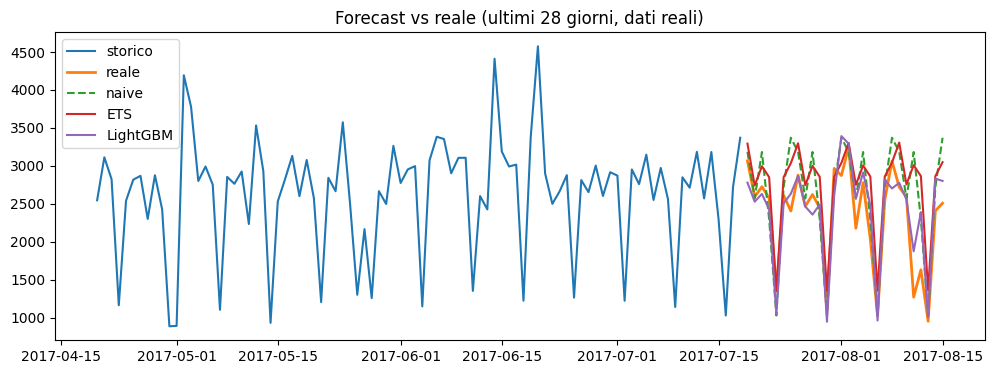

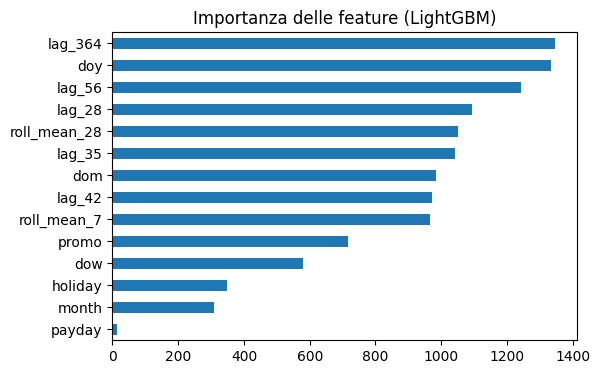

In [ ]:
end = len(y) - H
tr, te = y.iloc[:end], y.iloc[end:]
p_lgb, model = lgbm_forecast(X, y, end, H)

plt.figure(figsize=(12, 4))
plt.plot(tr.index[-90:], tr.values[-90:], label="storico")
plt.plot(te.index, te.values, label="actual", linewidth=2)
plt.plot(te.index, naive_seasonal(tr, H), "--", label="naive")
plt.plot(te.index, ets(tr, H), label="ETS")
plt.plot(te.index, p_lgb, label="LightGBM")
plt.legend(); plt.title("Forecast vs actual (last 28 days, real data)")
plt.savefig("forecast_real.png", dpi=150, bbox_inches="tight")
plt.show()

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(6, 4), title="Feature importance (LightGBM)")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Print the results table in Markdown format: copy it into the text cell below
print(summary.to_markdown())

| model          |   MAPE |   RMSE |   MASE |
|:-----------------|-------:|-------:|-------:|
| ETS              |  20.42 | 572.92 |   1.02 |
| LightGBM         |  19.34 | 547.6  |   1.02 |
| naive stagionale |  21.88 | 621.43 |   1.16 |


## 7. Results

Expanding-window backtesting, 28-day horizon, on a real series (store 1, family GROCERY I) of the Store Sales dataset.

| model          |  MAPE |   RMSE |  MASE |
|:-----------------|------:|-------:|------:|
| naive stagionale | 21.88 | 621.43 |  1.16 |
| ETS              | 20.42 | 572.92 |  1.02 |
| LightGBM         | 19.34 |  547.6 |  1.02 |

**What I observe**
- LightGBM is the best model but the advantage is small: about -12% MAPE and RMSE compared with the seasonal naive. ETS is almost on par (same MASE).
- On real data the gap between models shrinks a lot compared with synthetic data: holidays, promotions and external shocks limit single-series models.
- Limits: a single series, no hyperparameter tuning, ~12 backtest windows (small differences may not be significant).
- Next steps: a global model trained on all series (stores x families), which is where LightGBM tends to do best, and error analysis per window.

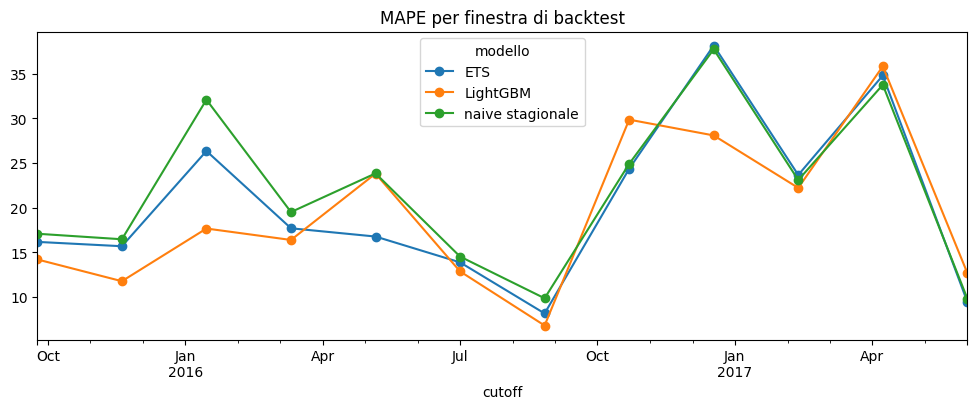

In [ ]:
res.pivot(index="cutoff", columns="model", values="MAPE").plot(
    figsize=(12, 4), marker="o", title="MAPE per backtest window")
plt.show()